# Teaching Stable Diffusion an Interior Style with LoRA

**Goal.** Teach Stable Diffusion 1.5 a specific interior style (here: **Japandi**, a mix of Japanese and Scandinavian design) from only ~20 photos, then **measure** how well it learned the style.

### What is LoRA?
A model like Stable Diffusion has huge weight matrices. Fine-tuning all of them needs a lot of memory and gives a 4 GB file.
**LoRA (Low-Rank Adaptation)** freezes the original model and learns a small *update* for some layers:

$$W_{new} = W + B \cdot A$$

If $W$ is 320×320 (about 102,000 numbers), $A$ is 8×320 and $B$ is 320×8, so the update has only about 5,000 numbers. The `8` is the **rank**: higher rank = more capacity, bigger file.
Result: training fits on a free T4 GPU, and the LoRA file is only a few MB. You can switch it on and off, and choose how strong it is.

### Plan
1. Train a LoRA on ~20 Japandi interior photos with a trigger word (`jpdi`).
2. Generate the same prompts **without** and **with** the LoRA (strength 0, 0.5, 1.0).
3. Measure with CLIP:
   - **Style similarity**: how close the images are to the training photos (higher = style learned)
   - **Prompt match**: is a bedroom still a bedroom? (should stay high)
   - **Memorization**: is the model just copying a training photo? (very high = bad)
4. Bonus: apply the LoRA to my own room photos with ControlNet, keeping the geometry.

## 1. Setup

In [ ]:
!pip uninstall -y torchao
!pip install -q diffusers transformers accelerate peft opencv-python

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 2. Check the GPU (must print True and Tesla T4)

In [ ]:
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))

2.11.0+cu130 True Tesla T4


## 3. Upload the training photos
Upload **15–25 photos** of the same style, either as separate images or as one `.zip` file.
- **Colab:** a file picker opens when you run the cell.
- **Kaggle:** first click *Add Input → Upload* and upload the photos as a dataset. The cell finds them in `/kaggle/input`. Put your own room photo in the same dataset with a name starting with `my_room` (for section 11).
Good training data: one consistent style, different rooms and angles, no text or watermarks.

Saving bedroom_01.jpg to bedroom_01.jpg
Saving bedroom_02.jpg to bedroom_02.jpg
Saving bedroom_03.jpg to bedroom_03.jpg
Saving bedroom_04.jpg to bedroom_04.jpg
Saving bedroom_05.webp to bedroom_05.webp
Saving detail_01.jpg to detail_01.jpg
Saving dining_01.jpg to dining_01.jpg
Saving dining_02.jpg to dining_02.jpg
Saving kitchen_01.jpg to kitchen_01.jpg
Saving kitchen_02.jpg to kitchen_02.jpg
Saving living_01.jpg to living_01.jpg
Saving living_02.jpg to living_02.jpg
Saving living_03.jpg to living_03.jpg
Saving living_04.jpg to living_04.jpg
Saving living_05.jpg to living_05.jpg
Saving living_06.webp to living_06.webp
Saving living_07.jpg to living_07.jpg
17 training images


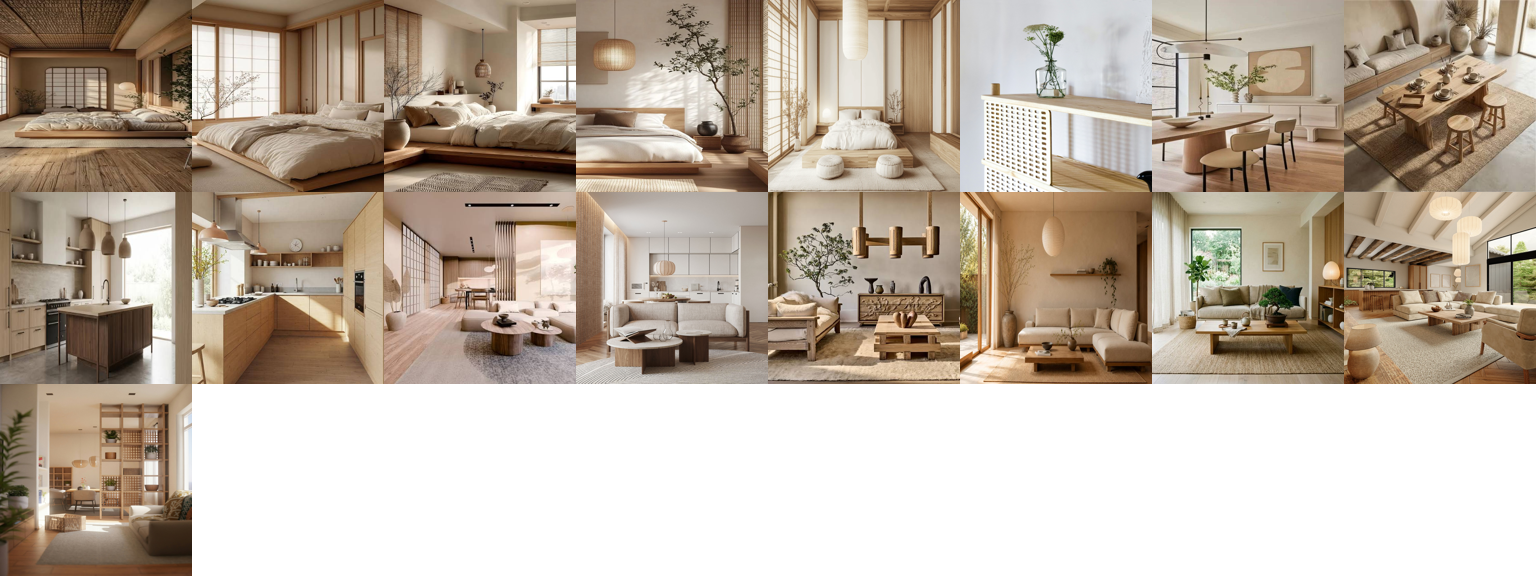

In [ ]:
import os, io, glob, zipfile
import numpy as np
from PIL import Image
IMG_EXT = (".jpg", ".jpeg", ".png", ".webp")
IN_COLAB = "google.colab" in str(get_ipython())
os.makedirs("train_images", exist_ok=True)

if IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    for name, data in uploaded.items():
        if name.lower().endswith(".zip"):
            zipfile.ZipFile(io.BytesIO(data)).extractall("train_images")
        else:
            open(os.path.join("train_images", name), "wb").write(data)
    src = "train_images"
else:  # Kaggle: photos come from the uploaded dataset
    for z in glob.glob("/kaggle/input/**/*.zip", recursive=True):
        zipfile.ZipFile(z).extractall("train_images")
    src = "/kaggle/input"

paths = sorted(p for p in glob.glob(f"{src}/**/*", recursive=True) + glob.glob("train_images/**/*", recursive=True)
               if p.lower().endswith(IMG_EXT) and not os.path.basename(p).lower().startswith("my_room"))
paths = sorted(set(paths))
print(len(paths), "training images")

def show_grid(imgs, size=192, cols=8):
    rows = (len(imgs) + cols - 1) // cols
    grid = Image.new("RGB", (cols * size, rows * size), "white")
    for i, im in enumerate(imgs):
        grid.paste(im.convert("RGB").resize((size, size)), ((i % cols) * size, (i // cols) * size))
    display(grid)
    return grid

show_grid([Image.open(p) for p in paths]);

## 4. Settings

In [ ]:
BASE = "stable-diffusion-v1-5/stable-diffusion-v1-5"
TRIGGER = "jpdi"                                   # a new word the model will connect to the style
ROOM_WORDS = {"living": "living room", "bedroom": "bedroom", "dining": "dining room",
              "kitchen": "kitchen", "detail": "interior detail"}
def caption_for(path):
    # the room type comes from the file name (living_01.jpg -> "living room"); unknown names -> "interior"
    prefix = os.path.basename(path).split("_")[0].lower()
    return f"a photo of a {TRIGGER} style {ROOM_WORDS.get(prefix, 'interior')}"
RES = 512                                          # SD 1.5 was trained on 512x512
RANK = 8                                           # LoRA rank (capacity)
LR = 1e-4                                          # learning rate
STEPS = 800                                        # about 45 passes over 17 images
SEED = 42

## 5. Prepare the data
Each photo is cropped to a square, resized to 512×512 and turned into a **latent** with the VAE (the compressed 64×64 form that Stable Diffusion works with). A flipped copy is added for variety.
Each photo gets its own caption with the room type from its file name, for example *"a photo of a jpdi style bedroom"*. This way the room word explains **what** is in the photo, and the trigger word `jpdi` only has to learn the **style**. The captions are turned into text embeddings once. After that, the VAE and the text encoder are removed from the GPU to free memory.

In [ ]:
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL

def to_tensor(p):
    img = Image.open(p).convert("RGB")
    w, h = img.size; s = min(w, h)
    img = img.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s)).resize((RES, RES), Image.BICUBIC)
    return torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 127.5 - 1   # values in [-1, 1]

vae = AutoencoderKL.from_pretrained(BASE, subfolder="vae", torch_dtype=torch.float16).to("cuda")
tokenizer = CLIPTokenizer.from_pretrained(BASE, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(BASE, subfolder="text_encoder", torch_dtype=torch.float16).to("cuda")

latents, text_embs = [], []
with torch.no_grad():
    for p in paths:
        ids = tokenizer(caption_for(p), padding="max_length", max_length=tokenizer.model_max_length,
                        truncation=True, return_tensors="pt").input_ids.cuda()
        emb = text_encoder(ids)[0]
        x = to_tensor(p)
        for img in (x, torch.flip(x, dims=[2])):                     # original + horizontal flip
            lat = vae.encode(img.unsqueeze(0).half().cuda()).latent_dist.sample()
            latents.append(lat * vae.config.scaling_factor)
            text_embs.append(emb)

for p in paths:
    print(f"{os.path.basename(p):18s} -> {caption_for(p)}")
print(len(latents), "latents of shape", tuple(latents[0].shape))
del vae, text_encoder; torch.cuda.empty_cache()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

vae/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B /  492MB            

text_encoder/model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

bedroom_01.jpg     -> a photo of a jpdi style bedroom
bedroom_02.jpg     -> a photo of a jpdi style bedroom
bedroom_03.jpg     -> a photo of a jpdi style bedroom
bedroom_04.jpg     -> a photo of a jpdi style bedroom
bedroom_05.webp    -> a photo of a jpdi style bedroom
detail_01.jpg      -> a photo of a jpdi style interior detail
dining_01.jpg      -> a photo of a jpdi style dining room
dining_02.jpg      -> a photo of a jpdi style dining room
kitchen_01.jpg     -> a photo of a jpdi style kitchen
kitchen_02.jpg     -> a photo of a jpdi style kitchen
living_01.jpg      -> a photo of a jpdi style living room
living_02.jpg      -> a photo of a jpdi style living room
living_03.jpg      -> a photo of a jpdi style living room
living_04.jpg      -> a photo of a jpdi style living room
living_05.jpg      -> a photo of a jpdi style living room
living_06.webp     -> a photo of a jpdi style living room
living_07.jpg      -> a photo of a jpdi style living room
34 latents of shape (1, 4, 64, 64)


## 6. Add LoRA to the UNet
The UNet is the part of Stable Diffusion that removes noise. It stays **frozen**; LoRA adds small trainable matrices to its attention layers (`to_q`, `to_k`, `to_v`, `to_out`).

In [ ]:
from diffusers import UNet2DConditionModel, DDPMScheduler
from diffusers.training_utils import cast_training_params
from peft import LoraConfig

unet = UNet2DConditionModel.from_pretrained(BASE, subfolder="unet", torch_dtype=torch.float16).to("cuda")
unet.requires_grad_(False)
unet.add_adapter(LoraConfig(r=RANK, lora_alpha=RANK, init_lora_weights="gaussian",
                            target_modules=["to_k", "to_q", "to_v", "to_out.0"]))
cast_training_params(unet, dtype=torch.float32)      # LoRA weights in full precision for stable training
unet.enable_gradient_checkpointing()                 # saves memory

trainable = [p for p in unet.parameters() if p.requires_grad]
n_train = sum(p.numel() for p in trainable); n_all = sum(p.numel() for p in unet.parameters())
print(f"Trainable: {n_train:,} of {n_all:,} parameters ({100 * n_train / n_all:.2f}%)")

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

unet/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

Trainable: 1,594,368 of 861,115,332 parameters (0.19%)


## 7. Train
Each step: take a training latent, add random noise at a random strength, and ask the UNet to predict that noise. The loss is how wrong the prediction is. Only the LoRA weights change.
Takes about 10 minutes on a T4.

In [ ]:
import time
import torch.nn.functional as F

noise_scheduler = DDPMScheduler.from_pretrained(BASE, subfolder="scheduler")
optimizer = torch.optim.AdamW(trainable, lr=LR, weight_decay=1e-2)
scaler = torch.amp.GradScaler("cuda")
gen = torch.Generator().manual_seed(SEED)
torch.manual_seed(SEED)

losses, t0 = [], time.time()
unet.train()
for step in range(1, STEPS + 1):
    i = torch.randint(len(latents), (1,), generator=gen).item()
    lat, text_emb = latents[i], text_embs[i]
    noise = torch.randn_like(lat)
    t = torch.randint(0, noise_scheduler.config.num_train_timesteps, (1,), device="cuda").long()
    noisy = noise_scheduler.add_noise(lat, noise, t)

    with torch.autocast("cuda", dtype=torch.float16):
        pred = unet(noisy, t, text_emb).sample
    loss = F.mse_loss(pred.float(), noise.float())

    optimizer.zero_grad()
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()
    losses.append(loss.item())
    if step % 100 == 0:
        print(f"step {step}/{STEPS}  loss {np.mean(losses[-100:]):.4f}  ({time.time() - t0:.0f} s)")

print(f"Training time: {(time.time() - t0) / 60:.1f} min, peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

step 100/800  loss 0.1500  (36 s)
step 200/800  loss 0.1221  (74 s)
step 300/800  loss 0.1210  (111 s)
step 400/800  loss 0.1287  (147 s)
step 500/800  loss 0.1454  (185 s)
step 600/800  loss 0.1102  (222 s)
step 700/800  loss 0.1140  (258 s)
step 800/800  loss 0.1442  (295 s)
Training time: 4.9 min, peak GPU memory: 2.1 GB


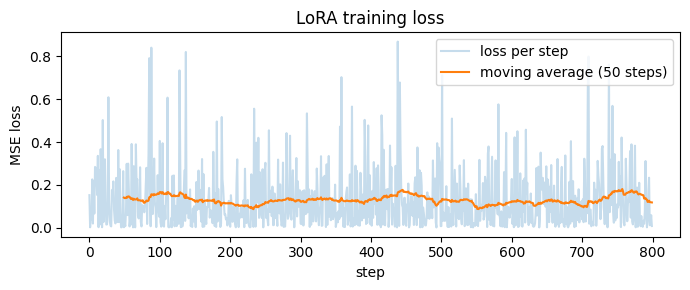

In [ ]:
import matplotlib.pyplot as plt
smooth = np.convolve(losses, np.ones(50) / 50, mode="valid")
plt.figure(figsize=(7, 3))
plt.plot(losses, alpha=0.25, label="loss per step")
plt.plot(range(49, len(losses)), smooth, label="moving average (50 steps)")
plt.xlabel("step"); plt.ylabel("MSE loss"); plt.legend(); plt.title("LoRA training loss")
plt.tight_layout(); plt.savefig("lora_loss.png", dpi=150); plt.show()

*Note: diffusion loss is very noisy, because every step uses a random noise level. A flat or slowly falling average is normal; the real test is the images.*

## 8. Save the LoRA

In [ ]:
from peft.utils import get_peft_model_state_dict
from diffusers.utils import convert_state_dict_to_diffusers
from diffusers import StableDiffusionPipeline

lora_state = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet))
StableDiffusionPipeline.save_lora_weights("jpdi_lora", unet_lora_layers=lora_state, safe_serialization=True)
size_mb = sum(os.path.getsize(f) for f in glob.glob("jpdi_lora/*")) / 1e6
print(f"LoRA saved: {size_mb:.1f} MB (the full model is about 4,000 MB)")

del unet, optimizer; torch.cuda.empty_cache()

LoRA saved: 6.4 MB (the full model is about 4,000 MB)


## 9. Without vs with LoRA
Same prompts and seeds, LoRA strength 0 (off), 0.5 and 1.0. Two room types (bathroom, office) may not be in the training photos: they test if the style **transfers** to new rooms.

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

...

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/n

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

living room: LoRA strength 0 | 0.5 | 1.0


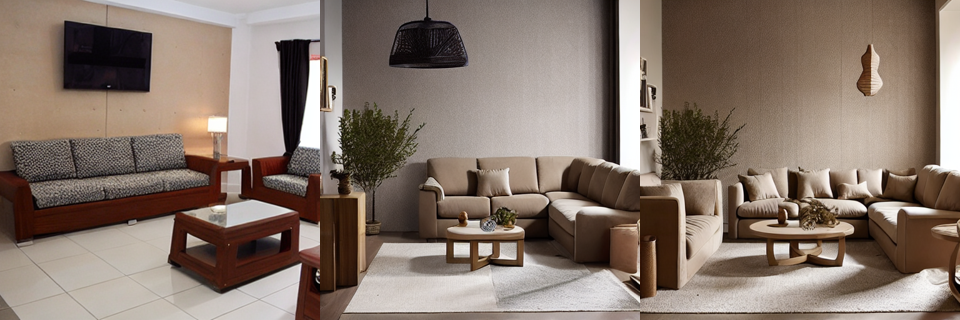

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

bedroom: LoRA strength 0 | 0.5 | 1.0


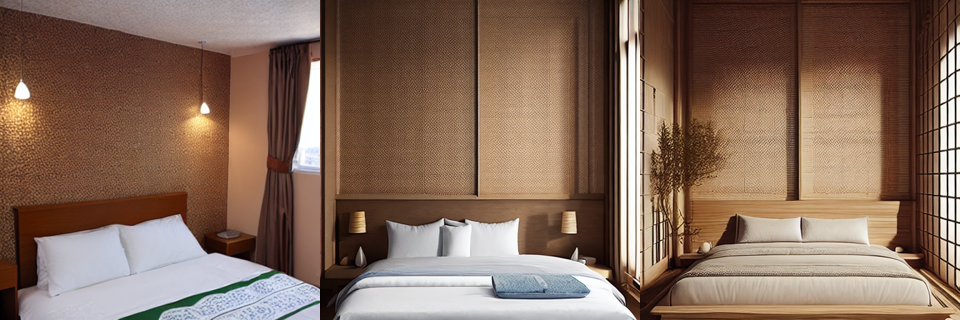

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

kitchen: LoRA strength 0 | 0.5 | 1.0


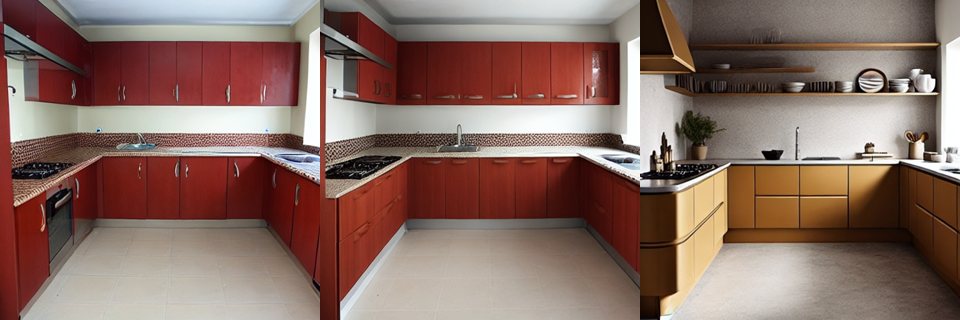

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

bathroom: LoRA strength 0 | 0.5 | 1.0


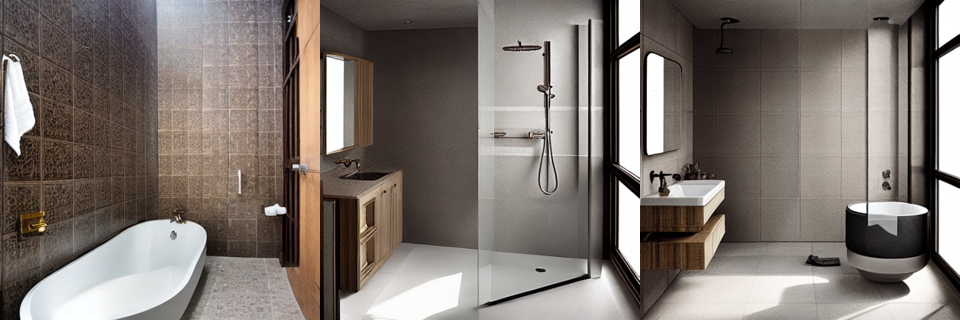

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

home office: LoRA strength 0 | 0.5 | 1.0


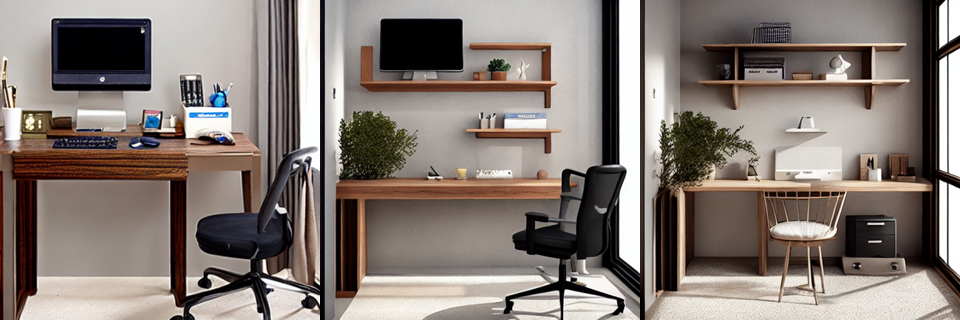

In [ ]:
pipe = StableDiffusionPipeline.from_pretrained(BASE, torch_dtype=torch.float16, safety_checker=None).to("cuda")
pipe.load_lora_weights("jpdi_lora")

rooms = ["living room", "bedroom", "kitchen", "bathroom", "home office"]
scales = [0.0, 0.5, 1.0]
negative = "blurry, distorted, low quality, deformed, text, watermark"
generated = {}   # (room, scale) -> image

for room in rooms:
    row = []
    for s in scales:
        img = pipe(f"a photo of a {TRIGGER} style {room}", negative_prompt=negative,
                   num_inference_steps=25, guidance_scale=7.5,
                   cross_attention_kwargs={"scale": s},
                   generator=torch.manual_seed(SEED)).images[0]
        generated[(room, s)] = img
        img.save(f"gen_{room.replace(' ', '_')}_scale{s}.jpg", quality=90)
        row.append(img)
    print(f"{room}: LoRA strength 0 | 0.5 | 1.0")
    show_grid(row, size=320, cols=3).save(f"compare_{room.replace(' ', '_')}.jpg", quality=90)

## 10. Measure with CLIP
CLIP turns images and texts into vectors; similar things get similar vectors.
- **Style similarity**: cosine between a generated image and the *average* of the training photos. Higher = closer to the style.
- **Prompt match**: cosine between the image and "a photo of a {room}". It should stay high, so a bedroom is still a bedroom.
- **Memorization**: cosine to the *most similar single* training photo. Around 0.95 or more would mean the model is copying.

In [ ]:
from transformers import CLIPModel, CLIPProcessor
import pandas as pd

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to("cuda").eval()
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

@torch.no_grad()
def img_emb(imgs):
    x = clip_proc(images=imgs, return_tensors="pt").to("cuda")
    e = clip.visual_projection(clip.vision_model(pixel_values=x["pixel_values"]).pooler_output)
    return e / e.norm(dim=-1, keepdim=True)

@torch.no_grad()
def txt_emb(texts):
    x = clip_proc(text=texts, return_tensors="pt", padding=True).to("cuda")
    e = clip.text_projection(clip.text_model(input_ids=x["input_ids"],
                                             attention_mask=x["attention_mask"]).pooler_output)
    return e / e.norm(dim=-1, keepdim=True)

train_e = img_emb([Image.open(p).convert("RGB") for p in paths])
style_center = train_e.mean(0); style_center = style_center / style_center.norm()

rows = []
for (room, s), img in generated.items():
    e = img_emb([img])[0]
    rows.append({"room": room, "LoRA strength": s,
                 "Style similarity ↑": float(e @ style_center),
                 "Prompt match ↑": float(e @ txt_emb([f"a photo of a {room}"])[0]),
                 "Memorization (max sim to a training photo) ↓": float((train_e @ e).max())})

df = pd.DataFrame(rows)
display(df.round(3))
summary = df.groupby("LoRA strength").mean(numeric_only=True).round(3)
display(summary)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

,room,LoRA strength,Style similarity ↑,Prompt match ↑,Memorization (max sim to a training photo) ↓
0,living room,0.0,0.777,0.264,0.783
1,living room,0.5,0.918,0.275,0.905
2,living room,1.0,0.928,0.272,0.913
3,bedroom,0.0,0.757,0.253,0.766
4,bedroom,0.5,0.871,0.264,0.897
5,bedroom,1.0,0.880,0.294,0.915
6,kitchen,0.0,0.753,0.296,0.787
7,kitchen,0.5,0.818,0.289,0.855
8,kitchen,1.0,0.880,0.295,0.920
9,bathroom,0.0,0.821,0.261,0.792


,Style similarity ↑,Prompt match ↑,Memorization (max sim to a training photo) ↓
LoRA strength,,,
0.0,0.775,0.274,0.775
0.5,0.854,0.273,0.858
1.0,0.881,0.285,0.887


**What I saw.**
- **Without LoRA (strength 0):** Stable Diffusion draws generic, dated rooms: red wooden furniture, patterned tiles, dark wood and busy decor. Average style similarity to the training photos is 0.775.
- **With LoRA (strength 1.0):** The rooms become clearly Japandi: light wood, beige and linen textures, low furniture, plants, paper or rattan lamps and shoji panels in the bedroom. Style similarity rises to 0.881 (+0.106), and prompt match stays the same (0.274 → 0.285), so a kitchen is still a kitchen and a bedroom is still a bedroom.
- **New rooms (bathroom, office):** These room types were not in the training photos. The office transfers well (0.768 → 0.858): light wood desk, wooden shelves, a plant and a rattan chair. The bathroom transfers only partly (0.821 → 0.858): a wooden vanity appears, but the palette stays grey.
- **What did not work:** At strength 0.5 the kitchen barely changed (red cabinets stay), while the living room already looked Japandi at 0.5 (style similarity 0.918). The training set had 7 living rooms but only 2 kitchens, so the style is learned more weakly for under-represented rooms. The bathroom at 0.5 also showed no gain (0.812 vs 0.821).
- **Memorization:** The highest similarity of any output to a single training photo is 0.920 (kitchen, strength 1.0), below the 0.95 level where I would suspect copying. Looking at the images confirms this: the outputs share the style, not the exact rooms.

**Result.** With 17 photos, 0.19% of the UNet parameters and 4.9 minutes of training on a free T4 GPU (2.1 GB peak memory), the LoRA learned the Japandi style. The result is a 6.4 MB file. It raises style similarity by 0.106 without hurting prompt match and without copying training photos, and the style transfers to room types it never saw. The weak spot is data balance: rooms with few training photos need a higher strength or more photos.

**Limits.** One seed per room and prompt, and CLIP-based metrics only, so the numbers show a direction, not a precise score. Part of the training set is AI-generated renders, not real photos. Next steps: add more kitchen and bathroom photos, try several seeds per prompt, and combine the LoRA with ControlNet to restyle a real room while keeping its layout.

## 12. Download the results

In [ ]:
df.to_csv("lora_metrics.csv", index=False)
!zip -q -r lora_results.zip jpdi_lora compare_*.jpg restyle_my_room.jpg lora_loss.png lora_metrics.csv
if IN_COLAB:
    files.download("lora_results.zip")
else:
    print("Kaggle: download lora_results.zip from the Output panel on the right (/kaggle/working)")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

*Optional: share the LoRA on the Hugging Face Hub*
```python
from huggingface_hub import notebook_login, create_repo, upload_folder
notebook_login()
create_repo("Mervecaliskan/japandi-interior-lora", exist_ok=True)
upload_folder(repo_id="Mervecaliskan/japandi-interior-lora", folder_path="jpdi_lora")
```